## Part 1 · State-based policy
### Setup: libraries, Google Drive, data
Installs `zarr`, imports the libraries, mounts Google Drive (checkpoints are saved there so they survive a Colab disconnect), prints which GPU we have, and downloads the Push-T demonstration data to Colab's fast local disk.

In [1]:
!pip -q install zarr

import os, zipfile, urllib.request, math, copy, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import zarr
from google.colab import drive

drive.mount("/content/drive")

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name     :", torch.cuda.get_device_name(0))

CKPT_DIR = Path("/content/drive/MyDrive/pusht_diffusion/checkpoints")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print("checkpoints go to:", CKPT_DIR)

# data goes on Colab's fast local disk
DATA_DIR  = Path("/content/data")
ZARR_PATH = DATA_DIR / "pusht" / "pusht_cchi_v7_replay.zarr"
URL = "https://diffusion-policy.cs.columbia.edu/data/training/pusht.zip"

if not ZARR_PATH.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = DATA_DIR / "pusht.zip"
    print("Downloading data...")
    urllib.request.urlretrieve(URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
    found = list(DATA_DIR.rglob("*.zarr"))
    assert found, "No .zarr folder found after unzipping"
    ZARR_PATH = found[0]
print("data at:", ZARR_PATH)

Mounted at /content/drive
GPU available: True
GPU name     : Tesla T4
checkpoints go to: /content/drive/MyDrive/pusht_diffusion/checkpoints
data at: /content/data/pusht/pusht_cchi_v7_replay.zarr


### Load the demonstrations
Opens the zarr file and reads the actions, the 9 block keypoints and the pusher position. The state observation is the keypoints (18 numbers) plus the pusher position (2 numbers) = **20 numbers per step**. `episode_ends` tells where each of the 206 episodes stops.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import zarr
from pathlib import Path

root = zarr.open(str(ZARR_PATH), mode="r")

action   = root["data"]["action"][:]
state    = root["data"]["state"][:]
keypoint = root["data"]["keypoint"][:]
episode_ends = root["meta"]["episode_ends"][:]

agent_pos = state[:, :2]
obs = np.concatenate([keypoint.reshape(len(keypoint), -1), agent_pos], axis=1)

print("obs:", obs.shape, " action:", action.shape, " episodes:", len(episode_ends))

obs: (25650, 20)  action: (25650, 2)  episodes: 206


### Normalise to [-1, 1]
Defines min-max normalisation for observations and actions (paper App. A.1) and its inverse. The network always works in the normalised range; we convert back to pixel units only when we send an action to the simulator.

In [3]:
def make_stats(arr):
    return {"min": arr.min(axis=0), "max": arr.max(axis=0)}

def normalize(x, stats):
    return 2 * (x - stats["min"]) / (stats["max"] - stats["min"]) - 1

def unnormalize(x_norm, stats):
    return (x_norm + 1) / 2 * (stats["max"] - stats["min"]) + stats["min"]

obs_stats    = make_stats(obs)
action_stats = make_stats(action)

obs_norm    = normalize(obs, obs_stats)
action_norm = normalize(action, action_stats)

### Check the normalisation
Checks that the normalised data really spans exactly -1 to +1 and that un-normalising gives back the original numbers (round-trip error must be tiny). Also saves the statistics to `norm_stats.npz`, because evaluation needs the same numbers.

In [4]:
print("normalized action: min", action_norm.min(axis=0), " max", action_norm.max(axis=0))
print("normalized obs   : min", obs_norm.min().round(3), " max", obs_norm.max().round(3))

# going back should give the original numbers
err_a = np.abs(unnormalize(action_norm, action_stats) - action).max()
err_o = np.abs(unnormalize(obs_norm, obs_stats) - obs).max()
print("round-trip error, action:", err_a, " obs:", err_o)

# save the stats for later notebooks (training and evaluation)
np.savez("norm_stats.npz",
         obs_min=obs_stats["min"], obs_max=obs_stats["max"],
         action_min=action_stats["min"], action_max=action_stats["max"])

normalized action: min [-1. -1.]  max [1. 1.]
normalized obs   : min -1.0  max 1.0
round-trip error, action: 7.6293945e-06  obs: 3.0517578e-05


### Training windows
For a time step *t*, builds one training example: the **last 2 observations** (the guide) and the **next 16 actions** (the target). Near the start or end of an episode the window is padded by repeating the first or last row, so it never crosses into another episode.

In [5]:
T_o, T_p = 2, 16

starts  = np.concatenate([[0], episode_ends[:-1]])
lengths = episode_ends - starts

# for every row, remember where its own episode starts and ends
ep_start = np.repeat(starts, lengths)
ep_end   = np.repeat(episode_ends, lengths)      # exclusive end

def get_window(i):
    """i = row index of the 'current time t'. Returns (obs window, action window)."""
    s, e = ep_start[i], ep_end[i]
    obs_idx = np.clip(np.arange(i - T_o + 1, i + 1), s, e - 1)
    act_idx = np.clip(np.arange(i, i + T_p),         s, e - 1)
    return obs_norm[obs_idx], action_norm[act_idx]

### Check the windows
Three checks: at the start of an episode both observations are identical (padding), in the middle the actions match a direct slice, and near the end the last actions repeat the final action.

In [6]:
for name, i in [("start of episode 0 ", starts[0]),
                ("middle of episode 0", starts[0] + 60),
                ("near the end       ", episode_ends[0] - 3)]:
    o, a = get_window(i)
    print(f"{name}: obs {o.shape}, action {a.shape}")

# at the start, both observations should be identical (padding)
o, a = get_window(starts[0])
print("start: the 2 observations are equal?", np.allclose(o[0], o[1]))

# in the middle, the window should match a direct slice
i = starts[0] + 60
o, a = get_window(i)
print("middle: actions match direct slice?", np.allclose(a, action_norm[i:i + T_p]))

# near the end, the last actions should repeat the final action of the episode
i = episode_ends[0] - 3
o, a = get_window(i)
print("end: last 3 action rows equal?", np.allclose(a[-1], a[-2]) and np.allclose(a[-2], a[-3]))

start of episode 0 : obs (2, 20), action (16, 2)
middle of episode 0: obs (2, 20), action (16, 2)
near the end       : obs (2, 20), action (16, 2)
start: the 2 observations are equal? True
middle: actions match direct slice? True
end: last 3 action rows equal? True


### PyTorch Dataset
Wraps `get_window` as a `Dataset`: each example is an observation block of shape (2, 20) and an action block of shape (16, 2), as float32 tensors.

In [7]:
import torch
from torch.utils.data import Dataset, DataLoader

class PushTDataset(Dataset):
    def __len__(self):
        return len(obs_norm)

    def __getitem__(self, i):
        o, a = get_window(i)
        return {
            "obs":    torch.from_numpy(o.astype(np.float32)),   # (2, 20)
            "action": torch.from_numpy(a.astype(np.float32)),   # (16, 2)
        }

dataset = PushTDataset()
print("number of examples:", len(dataset))

sample = dataset[100]
print("one example:", sample["obs"].shape, sample["action"].shape)

number of examples: 25650
one example: torch.Size([2, 20]) torch.Size([16, 2])


### DataLoader
Groups examples into batches of 256, shuffled each epoch. Prints the number of batches per epoch and the shapes and value ranges of one batch (everything should lie in [-1, 1]).

In [8]:
BATCH_SIZE = 256
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

print("batches per epoch:", len(loader))

batch = next(iter(loader))
print("obs   :", batch["obs"].shape,    batch["obs"].dtype)
print("action:", batch["action"].shape, batch["action"].dtype)
print("obs value range   :", batch["obs"].min().item(), "to", batch["obs"].max().item())
print("action value range:", batch["action"].min().item(), "to", batch["action"].max().item())

batches per epoch: 101
obs   : torch.Size([256, 2, 20]) torch.float32
action: torch.Size([256, 16, 2]) torch.float32
obs value range   : -1.0 to 1.0
action value range: -0.9879759550094604 to 1.0


### Noise schedule
Builds the squared-cosine schedule for K = 100 diffusion steps: `betas` (noise added per step), `alphas = 1 - betas`, and `alphas_cumprod` (alpha-bar, the fraction of the original signal still left after k steps). Prints a few values.

In [9]:
import math
import numpy as np
import torch
import matplotlib.pyplot as plt

K = 100   # number of diffusion steps (Table 7: D-Iters Train = 100)

def squared_cosine_betas(K, s=0.008, max_beta=0.999):
    def abar(u):                      # u goes from 0 to 1
        return math.cos((u + s) / (1 + s) * math.pi / 2) ** 2
    betas = []
    for i in range(K):
        t1, t2 = i / K, (i + 1) / K
        betas.append(min(1 - abar(t2) / abar(t1), max_beta))
    return torch.tensor(betas, dtype=torch.float32)

betas = squared_cosine_betas(K)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)      # this is alpha-bar

for k in [0, 10, 25, 50, 75, 90, 99]:
    print(f"k={k:2d}  beta={betas[k].item():.4f}  alpha_bar={alphas_cumprod[k].item():.4f}")

k= 0  beta=0.0006  alpha_bar=0.9994
k=10  beta=0.0055  alpha_bar=0.9667
k=25  beta=0.0134  alpha_bar=0.8356
k=50  beta=0.0315  alpha_bar=0.4783
k=75  beta=0.0747  alpha_bar=0.1335
k=90  beta=0.1888  alpha_bar=0.0195
k=99  beta=0.9990  alpha_bar=0.0000


### Plot the schedule
Plots beta, alpha-bar, and the mixing weights `sqrt(alpha_bar)` (clean signal) and `sqrt(1 - alpha_bar)` (noise) over k. Early steps keep mostly signal, late steps are almost pure noise.

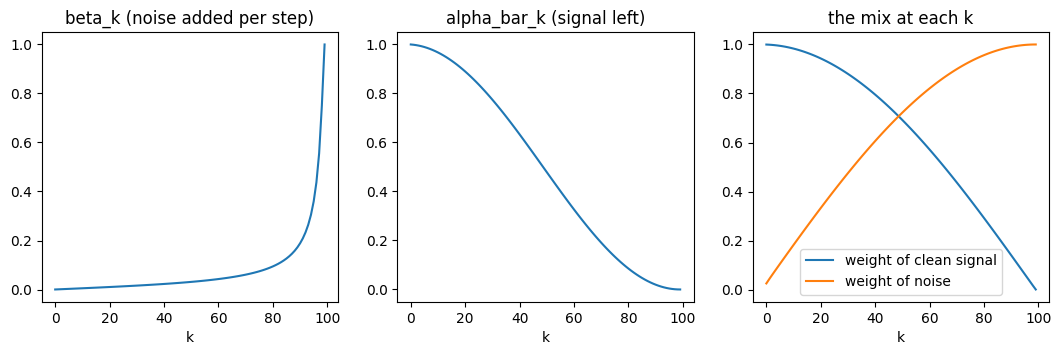

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].plot(betas.numpy())
axes[0].set_title("beta_k (noise added per step)")

axes[1].plot(alphas_cumprod.numpy())
axes[1].set_title("alpha_bar_k (signal left)")

axes[2].plot(torch.sqrt(alphas_cumprod).numpy(), label="weight of clean signal")
axes[2].plot(torch.sqrt(1 - alphas_cumprod).numpy(), label="weight of noise")
axes[2].set_title("the mix at each k")
axes[2].legend()

for ax in axes:
    ax.set_xlabel("k")
plt.show()

### Step embedding
The network must know *which noise level k* it is denoising. This function turns k into a 256-number vector of sines and cosines at different frequencies (as in Transformers).

In [11]:
def timestep_embedding(k, dim=256):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half) / half)   # from fast to slow waves
    args = k[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

ks = torch.arange(K)
emb = timestep_embedding(ks)
print("embedding shape:", emb.shape)     # (100, 256)

embedding shape: torch.Size([100, 256])


### Look at the step embedding
Left: the embedding of every k as an image. Right: how similar each k is to k = 50. Nearby noise levels get similar vectors, distant ones differ.

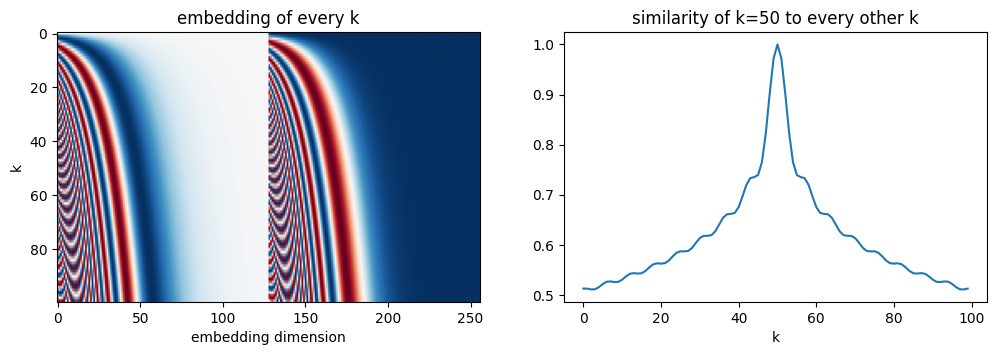

In [12]:
sim = torch.nn.functional.cosine_similarity(emb[50][None], emb, dim=-1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].imshow(emb.numpy(), aspect="auto", cmap="RdBu")
axes[0].set_xlabel("embedding dimension"); axes[0].set_ylabel("k")
axes[0].set_title("embedding of every k")
axes[1].plot(sim.numpy())
axes[1].set_xlabel("k"); axes[1].set_title("similarity of k=50 to every other k")
plt.show()

### Building blocks of the U-Net
`Conv1dBlock`: convolution, GroupNorm, Mish. `FiLMResBlock`: two such blocks plus a residual connection, where the condition (noise level + observation) is turned into a per-channel **scale and shift** (FiLM) applied to the features.

In [13]:
import torch.nn as nn

class Conv1dBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel=5, n_groups=8):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel, padding=kernel // 2),
            nn.GroupNorm(n_groups, out_ch),
            nn.Mish(),
        )
    def forward(self, x):
        return self.block(x)

class FiLMResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, cond_dim, kernel=5, n_groups=8):
        super().__init__()
        self.conv1 = Conv1dBlock(in_ch, out_ch, kernel, n_groups)
        self.conv2 = Conv1dBlock(out_ch, out_ch, kernel, n_groups)
        self.film  = nn.Linear(cond_dim, out_ch * 2)          # makes scale and shift
        self.res   = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, cond):
        out = self.conv1(x)                                    # (B, C, T)
        scale, shift = self.film(cond).chunk(2, dim=-1)        # each (B, C)
        out = scale[:, :, None] * out + shift[:, :, None]      # FiLM
        out = self.conv2(out)
        return out + self.res(x)

### Test one FiLM block
Feeds the same noisy actions with two different conditions and checks that the outputs differ (the condition really matters), and prints shapes and the parameter count.

In [14]:
block = FiLMResBlock(in_ch=2, out_ch=64, cond_dim=40 + 256)    # 40 = 2 obs x 20, 256 = k embedding

x = torch.randn(4, 2, 16)                  # 4 noisy action blocks, (channels=2, time=16)
cond_a = torch.randn(4, 296)
cond_b = torch.randn(4, 296)

out_a = block(x, cond_a)
out_b = block(x, cond_b)

print("input :", x.shape)
print("output:", out_a.shape)
print("same x, different condition -> outputs differ?", not torch.allclose(out_a, out_b))
print("number of parameters:", sum(p.numel() for p in block.parameters()))

input : torch.Size([4, 2, 16])
output: torch.Size([4, 64, 16])
same x, different condition -> outputs differ? True
number of parameters: 59712


### The full conditional 1D U-Net
Assembles the blocks into a U-Net over the 16-step action sequence: a down path, a middle, an up path with skip connections, and a final layer that predicts the noise. The condition is the step embedding joined with the flattened observation.

In [15]:
class ConditionalUnet1D(nn.Module):
    def __init__(self, action_dim=2, obs_dim=40, down_dims=(256, 512, 1024), embed_dim=256):
        super().__init__()
        self.embed_dim = embed_dim
        self.step_mlp = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 4), nn.Mish(), nn.Linear(embed_dim * 4, embed_dim))
        cond_dim = embed_dim + obs_dim

        dims = [action_dim, *down_dims]
        in_out = list(zip(dims[:-1], dims[1:]))

        self.down = nn.ModuleList()
        for i, (d_in, d_out) in enumerate(in_out):
            is_last = i == len(in_out) - 1
            self.down.append(nn.ModuleList([
                FiLMResBlock(d_in, d_out, cond_dim),
                FiLMResBlock(d_out, d_out, cond_dim),
                nn.Identity() if is_last else nn.Conv1d(d_out, d_out, 3, stride=2, padding=1),
            ]))

        mid = dims[-1]
        self.mid = nn.ModuleList([FiLMResBlock(mid, mid, cond_dim),
                                  FiLMResBlock(mid, mid, cond_dim)])

        self.up = nn.ModuleList()
        for d_in, d_out in reversed(in_out[1:]):
            self.up.append(nn.ModuleList([
                FiLMResBlock(d_out * 2, d_in, cond_dim),      # x2 because of the skip connection
                FiLMResBlock(d_in, d_in, cond_dim),
                nn.ConvTranspose1d(d_in, d_in, 4, stride=2, padding=1),
            ]))

        self.final = nn.Sequential(Conv1dBlock(down_dims[0], down_dims[0]),
                                   nn.Conv1d(down_dims[0], action_dim, 1))

    def forward(self, noisy_action, k, obs):
        # noisy_action: (B, 16, 2)   k: (B,)   obs: (B, 2, 20)
        x = noisy_action.transpose(1, 2)                          # (B, 2, 16)
        cond = torch.cat([self.step_mlp(timestep_embedding(k, self.embed_dim)),
                          obs.flatten(1)], dim=-1)                # (B, 296)
        skips = []
        for r1, r2, down in self.down:
            x = r1(x, cond); x = r2(x, cond)
            skips.append(x)
            x = down(x)
        for m in self.mid:
            x = m(x, cond)
        for r1, r2, up in self.up:
            x = torch.cat([x, skips.pop()], dim=1)
            x = r1(x, cond); x = r2(x, cond)
            x = up(x)
        return self.final(x).transpose(1, 2)                      # (B, 16, 2)

### Test the U-Net
Runs a random batch through a small version: checks the output shape (batch, 16, 2), counts parameters, and checks that changing the observation or the noise level k changes the output.

In [16]:
net = ConditionalUnet1D()                       # small version first

B = 4
a   = torch.randn(B, 16, 2)
k   = torch.randint(0, K, (B,))
obs = torch.randn(B, 2, 20)

out = net(a, k, obs)
print("output shape:", out.shape)
print("parameters  :", f"{sum(p.numel() for p in net.parameters()):,}")
print("observation matters?", not torch.allclose(out, net(a, k, torch.randn(B, 2, 20))))
print("k matters?          ", not torch.allclose(out, net(a, (k + 30) % K, obs)))

output shape: torch.Size([4, 16, 2])
parameters  : 65,783,298
observation matters? True
k matters?           True


### Step embedding, device-safe version
Same function as before, redefined so it also works when `k` lives on the GPU (the frequencies are created on the same device as `k`).

In [17]:
def timestep_embedding(k, dim=256):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=k.device) / half)
    args = k[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

### Training setup
Chooses the device, builds the full-size network (channels 256/512/1024, about 65.8M parameters) and its EMA copy, sets AdamW with a cosine learning-rate schedule and 500 warm-up steps, and defines `train_step`: add noise at a random level, predict the noise, MSE loss (paper Eq. 5), update the weights and the EMA.

In [18]:
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

DOWN_DIMS = (256, 512, 1024)        # small net (65.8M). Paper-size is (512, 1024, 2048)
EPOCHS = 4500
STEPS_PER_EPOCH = len(loader)
TOTAL_STEPS = EPOCHS * STEPS_PER_EPOCH
WARMUP = 500
SAVE_EVERY = 50                     # epochs (the paper's checkpoint interval)

net = ConditionalUnet1D(down_dims=DOWN_DIMS).to(device)
ema_net = copy.deepcopy(net).eval()
for p in ema_net.parameters():
    p.requires_grad_(False)

ab = alphas_cumprod.to(device)
optimizer = torch.optim.AdamW(net.parameters(), lr=1e-4, weight_decay=1e-6)

def lr_lambda(step):
    if step < WARMUP:
        return (step + 1) / WARMUP
    progress = (step - WARMUP) / max(1, TOTAL_STEPS - WARMUP)
    return 0.5 * (1 + math.cos(math.pi * progress))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

def update_ema(step, max_decay=0.9999):
    decay = min(max_decay, (1 + step) / (10 + step))
    with torch.no_grad():
        for p_ema, p in zip(ema_net.parameters(), net.parameters()):
            p_ema.mul_(decay).add_(p, alpha=1 - decay)

def train_step(batch, step):
    obs_b = batch["obs"].to(device)
    a0    = batch["action"].to(device)
    B = a0.shape[0]
    k     = torch.randint(0, K, (B,), device=device)
    noise = torch.randn_like(a0)
    ab_k  = ab[k][:, None, None]
    noisy = torch.sqrt(ab_k) * a0 + torch.sqrt(1 - ab_k) * noise
    pred = net(noisy, k, obs_b)
    loss = torch.nn.functional.mse_loss(pred, noise)          # Eq. 5
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    scheduler.step()
    update_ema(step)
    return loss.item()

# ---- checkpoints -------------------------------------------------------
start_epoch, global_step, epoch_losses = 0, 0, []

def save_checkpoints(epoch):
    # 1) full state, overwritten each time: lets us resume after a disconnect
    tmp = CKPT_DIR / "latest.tmp"
    torch.save({"epoch": epoch, "step": global_step, "epoch_losses": epoch_losses,
                "net": net.state_dict(), "ema": ema_net.state_dict(),
                "opt": optimizer.state_dict(), "sched": scheduler.state_dict()}, tmp)
    tmp.replace(CKPT_DIR / "latest.pt")
    # 2) small EMA-only snapshots (half precision) for evaluation later:
    #    every 250 epochs, plus the last 10 checkpoints of the run
    if epoch % 250 == 0 or epoch > EPOCHS - 500:
        ema16 = {k_: v.half() for k_, v in ema_net.state_dict().items()}
        torch.save({"epoch": epoch, "ema": ema16, "down_dims": DOWN_DIMS},
                   CKPT_DIR / f"ema_epoch_{epoch:04d}.pt")

latest = CKPT_DIR / "latest.pt"
if latest.exists():
    ck = torch.load(latest, map_location=device)
    net.load_state_dict(ck["net"]);  ema_net.load_state_dict(ck["ema"])
    optimizer.load_state_dict(ck["opt"]);  scheduler.load_state_dict(ck["sched"])
    start_epoch, global_step, epoch_losses = ck["epoch"], ck["step"], ck["epoch_losses"]
    print(f"resumed from epoch {start_epoch} (step {global_step})")
else:
    print("no checkpoint found: starting from scratch")
print(f"steps per epoch: {STEPS_PER_EPOCH},  total steps: {TOTAL_STEPS:,}")

device: cuda
resumed from epoch 4500 (step 454500)
steps per epoch: 101,  total steps: 454,500


### Speed benchmark
Times 40 training steps (after a few warm-up steps) to get seconds per step and project how long the whole 4500-epoch run will take.

In [19]:
def benchmark(n=40, warm=5):
    it = iter(loader)
    for i in range(warm):                      # warm-up steps, not timed
        train_step(next(it), i)
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for i in range(n):
        train_step(next(it), warm + i)
    if device == "cuda":
        torch.cuda.synchronize()
    s = (time.time() - t0) / n
    print(f"{s:.3f} s/step  |  {s * STEPS_PER_EPOCH / 60:.1f} min/epoch")
    print(f"projected time for {EPOCHS} epochs: {s * TOTAL_STEPS / 3600:.1f} hours")

benchmark()

0.305 s/step  |  0.5 min/epoch
projected time for 4500 epochs: 38.5 hours


### Training loop
Runs the epochs, records the mean loss of each epoch, prints progress with an estimate of the remaining time, and saves checkpoints every 50 epochs so training can be resumed after an interruption.

In [ ]:
def run_training(stop_after_hours=None):
    global global_step
    t_start = time.time()
    for epoch in range(start_epoch + 1, EPOCHS + 1):
        net.train()
        losses = []
        for batch in loader:
            losses.append(train_step(batch, global_step))
            global_step += 1
        epoch_losses.append(float(np.mean(losses)))

        if epoch == start_epoch + 1 or epoch % 10 == 0:
            done = epoch - start_epoch
            elapsed = (time.time() - t_start) / 3600
            left = elapsed / done * (EPOCHS - epoch)
            print(f"epoch {epoch:4d}/{EPOCHS}  loss {epoch_losses[-1]:.4f}  "
                  f"lr {scheduler.get_last_lr()[0]:.2e}  "
                  f"elapsed {elapsed:.2f}h  est. remaining {left:.1f}h")

        out_of_time = stop_after_hours and (time.time() - t_start) / 3600 >= stop_after_hours
        if epoch % SAVE_EVERY == 0 or epoch == EPOCHS or out_of_time:
            save_checkpoints(epoch)
            print(f"  -> checkpoint saved at epoch {epoch}")
        if out_of_time:
            print("stopping as requested; rerun Cell B and then this cell to continue")
            break

run_training()

epoch 3101/4500  loss 0.0006  lr 2.20e-05  elapsed 0.00h  est. remaining 3.0h
epoch 3110/4500  loss 0.0006  lr 2.17e-05  elapsed 0.02h  est. remaining 3.0h
epoch 3120/4500  loss 0.0006  lr 2.14e-05  elapsed 0.04h  est. remaining 3.0h
epoch 3130/4500  loss 0.0006  lr 2.11e-05  elapsed 0.07h  est. remaining 3.0h
epoch 3140/4500  loss 0.0007  lr 2.08e-05  elapsed 0.09h  est. remaining 3.0h
epoch 3150/4500  loss 0.0006  lr 2.06e-05  elapsed 0.11h  est. remaining 3.0h
  -> checkpoint saved at epoch 3150
epoch 3160/4500  loss 0.0007  lr 2.03e-05  elapsed 0.13h  est. remaining 3.0h
epoch 3170/4500  loss 0.0006  lr 2.00e-05  elapsed 0.16h  est. remaining 2.9h
epoch 3180/4500  loss 0.0006  lr 1.97e-05  elapsed 0.18h  est. remaining 2.9h
epoch 3190/4500  loss 0.0007  lr 1.94e-05  elapsed 0.20h  est. remaining 2.9h
epoch 3200/4500  loss 0.0005  lr 1.92e-05  elapsed 0.22h  est. remaining 2.9h
  -> checkpoint saved at epoch 3200
epoch 3210/4500  loss 0.0006  lr 1.89e-05  elapsed 0.24h  est. remaini

### DDPM sampler
Generates an action plan: start from pure noise and run the network 100 times from k = 99 down to 0. Each step estimates the clean action (clamped to [-1, 1]) and moves one step towards it, adding a little fresh noise except at the last step.

In [ ]:
alphas_d = alphas.to(device)
betas_d  = betas.to(device)
ab_prev  = torch.cat([torch.ones(1), alphas_cumprod[:-1]]).to(device)

@torch.no_grad()
def sample(model, obs_b):
    """obs_b: (B, 2, 20) normalized observations. Returns (B, 16, 2) normalized actions."""
    B = obs_b.shape[0]
    x = torch.randn(B, 16, 2, device=device)                       # pure noise
    for k in reversed(range(K)):
        kk  = torch.full((B,), k, device=device, dtype=torch.long)
        eps = model(x, kk, obs_b)

        x0 = (x - torch.sqrt(1 - ab[k]) * eps) / torch.sqrt(ab[k])  # estimate of the clean action
        x0 = x0.clamp(-1, 1)

        coef1 = torch.sqrt(ab_prev[k]) * betas_d[k] / (1 - ab[k])
        coef2 = torch.sqrt(alphas_d[k]) * (1 - ab_prev[k]) / (1 - ab[k])
        mean  = coef1 * x0 + coef2 * x

        if k > 0:
            var = betas_d[k] * (1 - ab_prev[k]) / (1 - ab[k])
            x = mean + torch.sqrt(var) * torch.randn_like(x)
        else:
            x = mean
    return x

## Part 2 · Evaluating the state-based policy
### Reconnect to Drive and check packages
Mounts Drive again (needed after a restart), lists the saved checkpoints with their sizes, installs the simulator's dependencies and checks that each one imports.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
CKPT_DIR = "/content/drive/MyDrive/pusht_diffusion/checkpoints"   # your checkpoints folder in Drive
for f in sorted(os.listdir(CKPT_DIR)):
    print(f"{f:28s} {os.path.getsize(os.path.join(CKPT_DIR, f))/1e6:8.1f} MB")

!pip -q install "pymunk==6.6.0" shapely pygame opencv-python-headless gym

import importlib
for name in ["pymunk", "shapely", "pygame", "cv2", "gym"]:
    try:
        m = importlib.import_module(name)
        print(f"{name:10s} OK  {getattr(m, '__version__', '')}")
    except Exception as e:
        print(f"{name:10s} FAILED  {type(e).__name__}: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ablation_results.json             0.0 MB
ablations.png                     0.1 MB
ema_epoch_0250.pt               131.6 MB
ema_epoch_0500.pt               131.6 MB
ema_epoch_0750.pt               131.6 MB
ema_epoch_1000.pt               131.6 MB
ema_epoch_1250.pt               131.6 MB
ema_epoch_1500.pt               131.6 MB
ema_epoch_1750.pt               131.6 MB
ema_epoch_2000.pt               131.6 MB
ema_epoch_2250.pt               131.6 MB
ema_epoch_2500.pt               131.6 MB
ema_epoch_2750.pt               131.6 MB
ema_epoch_3000.pt               131.6 MB
ema_epoch_3250.pt               131.6 MB
ema_epoch_3500.pt               131.6 MB
ema_epoch_3750.pt               131.6 MB
ema_epoch_4000.pt               131.6 MB
ema_epoch_4050.pt               131.6 MB
ema_epoch_4100.pt               131.6 MB
ema_epoch_4150.pt               131.6 MB
ema_epoch_

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


pygame 2.6.1 (SDL 2.28.4, Python 3.13.16)
Hello from the pygame community. https://www.pygame.org/contribute.html
pygame     OK  2.6.1
cv2        OK  5.0.0
gym        OK  0.25.2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


### Peek inside a checkpoint
Loads the epoch-4500 EMA checkpoint and prints what it contains (type, keys, the first value). Just a look before loading it for real.

In [ ]:
import torch

path = os.path.join(CKPT_DIR, "ema_epoch_4500.pt")
ck = torch.load(path, map_location="cpu")

print("type:", type(ck))
if isinstance(ck, dict):
    keys = list(ck.keys())
    print("number of keys:", len(keys))
    print("first 5 keys:", keys[:5])
    first = ck[keys[0]]
    print("first value:", type(first), getattr(first, "dtype", ""), getattr(first, "shape", ""))

type: <class 'dict'>
number of keys: 3
first 5 keys: ['epoch', 'ema', 'down_dims']
first value: <class 'int'>  


### Load the trained EMA model
Loads the EMA weights of epoch 4500 into the network and prints the epoch, channel sizes and number of parameters to confirm it loaded correctly.

In [ ]:
ck = torch.load(CKPT_DIR + "/ema_epoch_4500.pt", map_location="cpu")
print("epoch:", ck["epoch"], "| down_dims:", ck["down_dims"])

ema_net.load_state_dict({k: v.float() for k, v in ck["ema"].items()})
ema_net = ema_net.to(device).eval()

print("loaded OK, parameters:", f"{sum(p.numel() for p in ema_net.parameters()):,}")

epoch: 4500 | down_dims: (256, 512, 1024)
loaded OK, parameters: 65,783,298


### Sampler check with the trained model
Samples 8 action plans for one real observation and draws them against the human actions (red). The plans should lie close to what the human did.

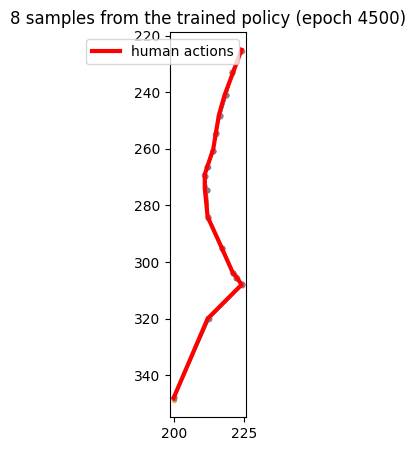

In [ ]:
i = int(starts[3]) + 40                      # a moment in the middle of episode 3
o, a_true = get_window(i)                    # normalized (2,20) and (16,2)

obs_b = torch.from_numpy(o.astype(np.float32))[None].repeat(8, 1, 1).to(device)
samples = sample(ema_net, obs_b).cpu().numpy()                      # (8, 16, 2) normalized

samples_px = unnormalize(samples, action_stats)                     # back to pixel units
a_true_px  = unnormalize(a_true,  action_stats)

plt.figure(figsize=(5, 5))
for s in samples_px:
    plt.plot(s[:, 0], s[:, 1], "-o", ms=3, alpha=0.6)
plt.plot(a_true_px[:, 0], a_true_px[:, 1], "r-", lw=3, label="human actions")
plt.gca().invert_yaxis(); plt.gca().set_aspect("equal")
plt.legend(); plt.title("8 samples from the trained policy (epoch 4500)")
plt.show()

### Push-T simulator
Clones the authors' official repository (the simulator is theirs; the policy is ours), works around a newer-matplotlib incompatibility, creates the keypoint environment, resets it with the first test seed and takes one no-op step to see the observation and reward.

In [ ]:
import sys, subprocess, os
os.environ["SDL_VIDEODRIVER"] = "dummy"          # pygame without a screen

if not os.path.exists("/content/diffusion_policy_official"):
    subprocess.run(["git", "clone", "-q", "--depth", "1",
                    "https://github.com/real-stanford/diffusion_policy",
                    "/content/diffusion_policy_official"], check=True)
sys.path.insert(0, "/content/diffusion_policy_official")

# newer matplotlib removed cm.get_cmap, which the official env code still calls
import matplotlib, matplotlib.cm as cm
if not hasattr(cm, "get_cmap"):
    cm.get_cmap = lambda name=None, lut=None: matplotlib.colormaps[name]

from diffusion_policy.env.pusht.pusht_keypoints_env import PushTKeypointsEnv

kp = PushTKeypointsEnv.genenerate_keypoint_manager_params()
env = PushTKeypointsEnv(legacy=True, render_size=96, **kp)

env.seed(100000)                                  # first test seed of the paper's protocol
o = env.reset()
print("raw observation shape:", o.shape)
print("first 20 values (what our policy uses):", o[:20].round(1))
print("agent position (last 2 of the 20):", o[18:20].round(1))

# take one step: move the pusher to its own position (no movement) and look at the reward
o, r, done, info = env.step(o[18:20])
print("reward after 1 step:", r, "| done:", done)

raw observation shape: (40,)
first 20 values (what our policy uses): [376.1 193.5 261.  192.4 336.1  96.4 319.5 161.2 387.5 232.1 349.5 134.8
 300.7 196.8 338.7 197.3 312.8 125.6 235.  124. ]
agent position (last 2 of the 20): [235. 124.]
reward after 1 step: 0.0 | done: False


/content/diffusion_policy_official/diffusion_policy/env/pusht/pymunk_keypoint_manager.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10')
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### One episode with receding-horizon control
`run_episode`: observe, sample a 16-step plan, execute the first 8 actions, then plan again, up to 300 steps or until coverage passes 95%. The score is the maximum reward reached. Tried on 5 test seeds first.

In [ ]:
def run_episode(model, seed, max_steps=300, T_o=2, T_a=8):
    """One episode with receding-horizon control. Returns the max reward reached."""
    env.seed(seed)
    o = env.reset()
    obs_hist = [o[:20]] * T_o                 # pad with the first observation, like in training
    max_r, steps, done = 0.0, 0, False
    while steps < max_steps and not done:
        obs_win = normalize(np.stack(obs_hist[-T_o:]), obs_stats).astype(np.float32)   # (2, 20)
        obs_b = torch.from_numpy(obs_win)[None].to(device)                              # (1, 2, 20)
        plan = sample(model, obs_b)[0].cpu().numpy()                                    # (16, 2) normalized
        plan = unnormalize(plan, action_stats)                                          # pixels (0..512)
        for a in plan[:T_a]:
            o, r, done, _ = env.step(a)
            obs_hist.append(o[:20])
            max_r = max(max_r, r)
            steps += 1
            if done or steps >= max_steps:
                break
    return max_r

import time
t0 = time.time()
scores = []
for seed in range(100000, 100005):
    s = run_episode(ema_net, seed)
    scores.append(s)
    print(f"seed {seed}: score {s:.3f}   ({time.time() - t0:.0f} s elapsed)")
print("mean score over these 5 seeds:", round(float(np.mean(scores)), 3))

seed 100000: score 1.000   (16 s elapsed)
seed 100001: score 0.985   (47 s elapsed)
seed 100002: score 1.000   (60 s elapsed)
seed 100003: score 0.179   (91 s elapsed)
seed 100004: score 0.997   (123 s elapsed)
mean score over these 5 seeds: 0.832


### Batched evaluation
`load_ema(epoch)` loads a checkpoint. `evaluate` runs many episodes **in lockstep**: one batched sampler call plans for all unfinished episodes. Defines the 6 training seeds (0 to 5) and the 50 test seeds (100000 to 100049).

In [ ]:
def load_ema(epoch):
    ck = torch.load(f"{CKPT_DIR}/ema_epoch_{epoch:04d}.pt", map_location="cpu")
    ema_net.load_state_dict({k: v.float() for k, v in ck["ema"].items()})
    return ema_net.to(device).eval()

TRAIN_SEEDS = list(range(0, 6))
TEST_SEEDS  = list(range(100000, 100050))

@torch.no_grad()
def evaluate(model, seeds, max_steps=300, T_o=2, T_a=8):
    """Run all seeds in lockstep. One batched sampler call plans for every unfinished episode."""
    envs = []
    for s in seeds:
        e = PushTKeypointsEnv(legacy=True, render_size=96, **kp)
        e.seed(s)
        envs.append(e)
    obs_hist = [[e.reset()[:20]] * T_o for e in envs]
    max_r  = np.zeros(len(envs))
    steps  = np.zeros(len(envs), dtype=int)
    done   = np.zeros(len(envs), dtype=bool)

    while not done.all():
        active = [i for i in range(len(envs)) if not done[i]]
        obs_win = np.stack([normalize(np.stack(obs_hist[i][-T_o:]), obs_stats) for i in active]).astype(np.float32)
        plans = sample(model, torch.from_numpy(obs_win).to(device)).cpu().numpy()    # (n_active, 16, 2)
        plans = unnormalize(plans, action_stats)
        for j, i in enumerate(active):
            for a in plans[j, :T_a]:
                o, r, d, _ = envs[i].step(a)
                obs_hist[i].append(o[:20])
                max_r[i] = max(max_r[i], r)
                steps[i] += 1
                if d or steps[i] >= max_steps:
                    done[i] = True
                    break
    return max_r

torch.manual_seed(0)
t0 = time.time()
model = load_ema(4500)
r_train = evaluate(model, TRAIN_SEEDS)
r_test  = evaluate(model, TEST_SEEDS)
print(f"epoch 4500 | train-seed score {r_train.mean():.3f} | test-seed score {r_test.mean():.3f} | {time.time()-t0:.0f} s")
print("test scores per seed:", np.round(r_test, 2))

epoch 4500 | train-seed score 0.994 | test-seed score 0.948 | 75 s
test scores per seed: [1.   0.99 1.   0.18 1.   1.   1.   1.   1.   0.99 0.98 1.   1.   1.
 1.   1.   1.   0.98 1.   1.   1.   0.96 0.98 0.96 0.96 1.   0.   1.
 1.   1.   0.51 1.   1.   0.96 0.97 1.   1.   1.   1.   1.   1.   1.
 0.99 1.   0.98 1.   1.   0.99 1.   1.  ]


### Evaluate the last 10 checkpoints
Evaluates the EMA checkpoints at epochs 4050, 4100, ..., 4500 on the training and test seeds, saves everything to `eval_results.json`, and prints the maximum and the average over the 10 checkpoints (the paper's reporting style).

In [ ]:
import json

EPOCHS_TO_EVAL = list(range(4050, 4501, 50))        # the last 10 checkpoints
results = {}
t0 = time.time()
for ep in EPOCHS_TO_EVAL:
    torch.manual_seed(ep)
    model = load_ema(ep)
    r_tr = evaluate(model, TRAIN_SEEDS)
    r_te = evaluate(model, TEST_SEEDS)
    results[ep] = {"train": r_tr.tolist(), "test": r_te.tolist()}
    print(f"epoch {ep} | train {r_tr.mean():.3f} | test {r_te.mean():.3f} | {time.time()-t0:.0f} s")

with open(f"{CKPT_DIR}/eval_results.json", "w") as f:
    json.dump(results, f)

test_means  = np.array([np.mean(results[e]["test"])  for e in EPOCHS_TO_EVAL])
train_means = np.array([np.mean(results[e]["train"]) for e in EPOCHS_TO_EVAL])
print()
print(f"test : max {test_means.max():.3f} | average of last 10 {test_means.mean():.3f} (std {test_means.std():.3f})")
print(f"train: max {train_means.max():.3f} | average of last 10 {train_means.mean():.3f}")

epoch 4050 | train 0.997 | test 0.966 | 81 s
epoch 4100 | train 0.998 | test 0.949 | 161 s
epoch 4150 | train 0.997 | test 0.950 | 240 s
epoch 4200 | train 0.999 | test 0.949 | 320 s
epoch 4250 | train 0.999 | test 0.949 | 402 s
epoch 4300 | train 0.997 | test 0.949 | 481 s
epoch 4350 | train 0.998 | test 0.950 | 562 s
epoch 4400 | train 0.999 | test 0.947 | 643 s
epoch 4450 | train 0.999 | test 0.950 | 722 s
epoch 4500 | train 1.000 | test 0.951 | 791 s

test : max 0.966 | average of last 10 0.951 (std 0.005)
train: max 1.000 | average of last 10 0.998


## Part 3 · Ablations (state-based)
### Action horizon T_a
Redefines `evaluate` so it can execute plan rows `[latency : latency + T_a]`, loads the epoch-4500 model, and runs T_a = 1, 2, 4, 8, 12, 16 on the test seeds (sampling seed 0). Results go to `ablation_results.json`.

In [ ]:
@torch.no_grad()
def evaluate(model, seeds, max_steps=300, T_o=2, T_a=8, latency=0):
    """Same as before, but executes plan rows [latency : latency + T_a]."""
    assert latency + T_a <= 16
    envs = []
    for s in seeds:
        e = PushTKeypointsEnv(legacy=True, render_size=96, **kp)
        e.seed(s)
        envs.append(e)
    obs_hist = [[e.reset()[:20]] * T_o for e in envs]
    max_r  = np.zeros(len(envs))
    steps  = np.zeros(len(envs), dtype=int)
    done   = np.zeros(len(envs), dtype=bool)

    while not done.all():
        active = [i for i in range(len(envs)) if not done[i]]
        obs_win = np.stack([normalize(np.stack(obs_hist[i][-T_o:]), obs_stats) for i in active]).astype(np.float32)
        plans = sample(model, torch.from_numpy(obs_win).to(device)).cpu().numpy()
        plans = unnormalize(plans, action_stats)
        for j, i in enumerate(active):
            for a in plans[j, latency:latency + T_a]:
                o, r, d, _ = envs[i].step(a)
                obs_hist[i].append(o[:20])
                max_r[i] = max(max_r[i], r)
                steps[i] += 1
                if d or steps[i] >= max_steps:
                    done[i] = True
                    break
    return max_r

model = load_ema(4500)
abl = {"T_a": {}, "latency": {}}
t0 = time.time()
for Ta in [1, 2, 4, 8, 12, 16]:
    torch.manual_seed(0)
    r = evaluate(model, TEST_SEEDS, T_a=Ta)
    abl["T_a"][Ta] = r.tolist()
    print(f"T_a = {Ta:2d} | test score {r.mean():.3f} | {time.time()-t0:.0f} s")

with open(f"{CKPT_DIR}/ablation_results.json", "w") as f:
    json.dump(abl, f)

T_a =  1 | test score 0.908 | 263 s
T_a =  2 | test score 0.906 | 399 s
T_a =  4 | test score 0.936 | 471 s
T_a =  8 | test score 0.965 | 514 s
T_a = 12 | test score 0.919 | 545 s
T_a = 16 | test score 0.877 | 572 s


> **Note:** this first latency cell used the *current* observation while skipping plan rows, which does not model latency. Its output is cleared; the corrected stale-observation version is in the next cell.

### Latency sweep (first version)
Runs latency 0, 2, 4, 6, 8 with the evaluate function above. As the note says, that version did not model latency correctly, so these results were discarded and the sweep is redone in the next cell.

In [ ]:
t0 = time.time()
for lat in [0, 2, 4, 6, 8]:
    runs = []
    for seed in range(3):
        torch.manual_seed(seed)
        runs.append(evaluate(model, TEST_SEEDS, T_a=8, latency=lat).mean())
    abl["latency"][lat] = [float(x) for x in runs]
    print(f"latency = {lat} | scores {np.round(runs, 3)} | mean {np.mean(runs):.3f} | {time.time()-t0:.0f} s")

with open(f"{CKPT_DIR}/ablation_results.json", "w") as f:
    json.dump(abl, f)

### Latency sweep (corrected)
Fixes `evaluate`: with latency L the policy sees an observation window that ends L steps in the past, so the first L plan rows are already past and rows `[L : L + T_a]` are executed. Reruns the sweep with 3 sampling seeds per setting.

In [ ]:
@torch.no_grad()
def evaluate(model, seeds, max_steps=300, T_o=2, T_a=8, latency=0):
    """Latency: the policy sees observations that are `latency` steps old; its first
    `latency` plan rows are already in the past, so rows [latency : latency + T_a] are executed."""
    assert latency + T_a <= 16
    envs = []
    for s in seeds:
        e = PushTKeypointsEnv(legacy=True, render_size=96, **kp)
        e.seed(s)
        envs.append(e)
    obs_hist = [[e.reset()[:20]] * (T_o + latency) for e in envs]    # padded with the first observation
    max_r  = np.zeros(len(envs))
    steps  = np.zeros(len(envs), dtype=int)
    done   = np.zeros(len(envs), dtype=bool)

    def window(h):
        end = len(h) - latency                       # newest observation the policy is allowed to see
        return h[end - T_o:end]

    while not done.all():
        active = [i for i in range(len(envs)) if not done[i]]
        obs_win = np.stack([normalize(np.stack(window(obs_hist[i])), obs_stats) for i in active]).astype(np.float32)
        plans = sample(model, torch.from_numpy(obs_win).to(device)).cpu().numpy()
        plans = unnormalize(plans, action_stats)
        for j, i in enumerate(active):
            for a in plans[j, latency:latency + T_a]:
                o, r, d, _ = envs[i].step(a)
                obs_hist[i].append(o[:20])
                max_r[i] = max(max_r[i], r)
                steps[i] += 1
                if d or steps[i] >= max_steps:
                    done[i] = True
                    break
    return max_r

abl["latency"] = {}
t0 = time.time()
for lat in [0, 2, 4, 6, 8]:
    runs = []
    for seed in range(3):
        torch.manual_seed(seed)
        runs.append(evaluate(model, TEST_SEEDS, T_a=8, latency=lat).mean())
    abl["latency"][lat] = [float(x) for x in runs]
    print(f"latency = {lat} | scores {np.round(runs, 3)} | mean {np.mean(runs):.3f} | {time.time()-t0:.0f} s")

with open(f"{CKPT_DIR}/ablation_results.json", "w") as f:
    json.dump(abl, f)

latency = 0 | scores [0.965 0.948 0.949] | mean 0.954 | 129 s
latency = 2 | scores [0.925 0.917 0.908] | mean 0.917 | 262 s
latency = 4 | scores [0.929 0.91  0.912] | mean 0.917 | 394 s
latency = 6 | scores [0.916 0.898 0.894] | mean 0.903 | 528 s
latency = 8 | scores [0.73  0.714 0.754] | mean 0.733 | 662 s


### More sampling seeds for T_a
Adds two more sampling seeds (1 and 2) for each T_a so every setting has 3 runs, then saves the results. Three runs per setting show how much of the difference is just sampling noise.

In [ ]:
abl["T_a_runs"] = {Ta: [float(np.mean(abl["T_a"][Ta]))] for Ta in [1, 2, 4, 8, 12, 16]}   # seed 0 from before
t0 = time.time()
for Ta in [1, 2, 4, 8, 12, 16]:
    for seed in (1, 2):
        torch.manual_seed(seed)
        abl["T_a_runs"][Ta].append(float(evaluate(model, TEST_SEEDS, T_a=Ta).mean()))
    print(f"T_a = {Ta:2d} | scores {np.round(abl['T_a_runs'][Ta], 3)} | mean {np.mean(abl['T_a_runs'][Ta]):.3f} | {time.time()-t0:.0f} s")

with open(f"{CKPT_DIR}/ablation_results.json", "w") as f:
    json.dump(abl, f)

T_a =  1 | scores [0.908 0.908 0.894] | mean 0.903 | 528 s
T_a =  2 | scores [0.906 0.906 0.907] | mean 0.906 | 800 s
T_a =  4 | scores [0.936 0.935 0.936] | mean 0.936 | 947 s
T_a =  8 | scores [0.965 0.948 0.949] | mean 0.954 | 1031 s
T_a = 12 | scores [0.919 0.917 0.941] | mean 0.925 | 1095 s
T_a = 16 | scores [0.877 0.841 0.843] | mean 0.854 | 1149 s


### Ablation figure
Plots the mean test score (with std over the 3 runs) against T_a and against latency.

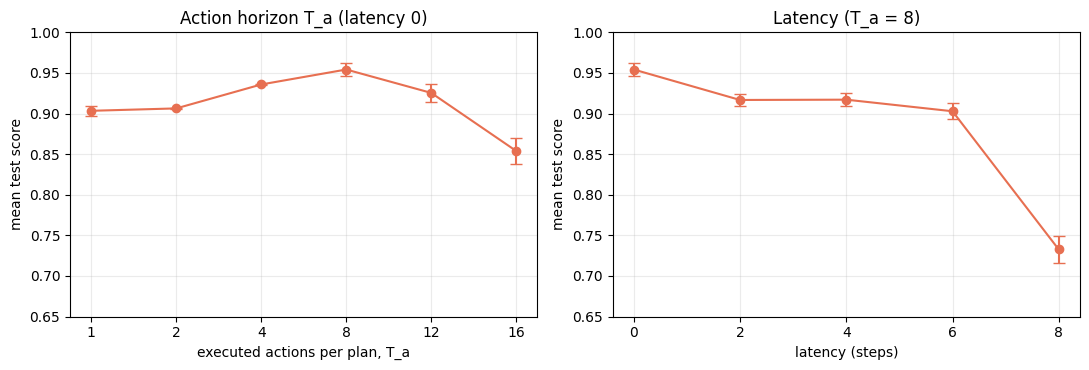

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
Tas  = [1, 2, 4, 8, 12, 16]
lats = [0, 2, 4, 6, 8]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, xs, runs, title, xlabel in [
    (axes[0], Tas,  [abl["T_a_runs"][t] for t in Tas],  "Action horizon T_a (latency 0)", "executed actions per plan, T_a"),
    (axes[1], lats, [abl["latency"][l]  for l in lats], "Latency (T_a = 8)",               "latency (steps)")]:
    m = [np.mean(r) for r in runs]; sd = [np.std(r) for r in runs]
    ax.errorbar(range(len(xs)), m, yerr=sd, fmt="o-", capsize=4, color="#e76f51")
    ax.set_xticks(range(len(xs))); ax.set_xticklabels(xs)
    ax.set_xlabel(xlabel); ax.set_ylabel("mean test score"); ax.set_title(title)
    ax.set_ylim(0.65, 1.0); ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(f"{CKPT_DIR}/ablations.png", dpi=150)
plt.show()

### Simulator for the image-based part
Reinstalls the simulator dependencies and re-imports the official environment (including `PushTImageEnv`), because Colab may have restarted since the state-based part.

In [31]:
!pip -q install "pymunk==6.6.0" shapely pygame opencv-python-headless gym

import sys, subprocess, os
os.environ["SDL_VIDEODRIVER"] = "dummy"            # pygame without a screen

if not os.path.exists("/content/diffusion_policy_official"):
    subprocess.run(["git", "clone", "-q", "--depth", "1",
                    "https://github.com/real-stanford/diffusion_policy",
                    "/content/diffusion_policy_official"], check=True)
sys.path.insert(0, "/content/diffusion_policy_official")

# newer matplotlib removed cm.get_cmap, which the official env code still calls
import matplotlib, matplotlib.cm as cm
if not hasattr(cm, "get_cmap"):
    cm.get_cmap = lambda name=None, lut=None: matplotlib.colormaps[name]

from diffusion_policy.env.pusht.pusht_image_env import PushTImageEnv
print("simulator import OK")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


simulator import OK


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


> **Note:** the original output of this cell was a `NameError` from a notebook restart (variables from earlier cells were gone). Output cleared; re-run after the state-pipeline cells.

### Raw weights vs EMA weights
Evaluates the raw (non-EMA) weights from `latest.pt` with 3 sampling seeds and compares them with the EMA results from before. At the end of the cosine schedule the two are almost the same, which does not prove EMA is unnecessary.

In [32]:
raw_ck = torch.load(f"{CKPT_DIR}/latest.pt", map_location="cpu")
print("latest.pt is epoch:", raw_ck["epoch"])

raw_model = copy.deepcopy(ema_net)
raw_model.load_state_dict({k: v.float() for k, v in raw_ck["net"].items()})
raw_model = raw_model.to(device).eval()

raw_runs = []
for seed in range(3):
    torch.manual_seed(seed)
    raw_runs.append(float(evaluate(raw_model, TEST_SEEDS, T_a=8).mean()))
print("raw weights, 3 sampling seeds:", np.round(raw_runs, 3), "| mean", round(float(np.mean(raw_runs)), 3))
print("EMA weights (from before)   : [0.965 0.948 0.949] | mean 0.954")

abl["raw_vs_ema"] = {"raw": raw_runs, "ema": [0.965, 0.948, 0.949]}
with open(f"{CKPT_DIR}/ablation_results.json", "w") as f:
    json.dump(abl, f)

## Part 4 · Image-based policy
### Load the camera images
Reads the 96×96 image array from the zarr file and starts converting it to a compact `uint8` array in memory (this cell is the beginning of the conversion; the next cell finishes and checks it).

In [22]:
raw_img = root["data"]["img"]                      # the image array inside the zarr file
N = raw_img.shape[0]                               # 25650, taken from the image array itself
imgs = np.empty((N, 96, 96, 3), dtype=np.uint8)
# ... the rest of the cell stays exactly as you have it

### Convert and verify the images
Converts all 25,650 frames to `uint8` and checks the conversion lost nothing (all values were whole numbers 0 to 255). Also checks that the pusher position lines up with the pusher in the picture.

uint8 images: (25650, 96, 96, 3) uint8 | size: 709 MB
conversion lossless: True
agent_pos rows: (25650, 2)


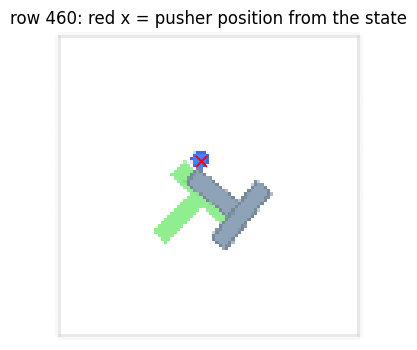

In [23]:
N = raw_img.shape[0]                               # 25650, taken from the image array itself
imgs = np.empty((N, 96, 96, 3), dtype=np.uint8)

lossless = True
for s in range(0, N, 2000):
    chunk = raw_img[s:s + 2000]
    c8 = chunk.astype(np.uint8)
    lossless &= bool(np.array_equal(chunk, c8))    # are all values whole numbers in 0..255?
    imgs[s:s + 2000] = c8

print("uint8 images:", imgs.shape, imgs.dtype, "| size:", round(imgs.nbytes / 1e6), "MB")
print("conversion lossless:", lossless)
print("agent_pos rows:", agent_pos.shape)           # should be (25650, 2)

# sanity check: the pusher position (field is 0..512) mapped onto the 96x96 picture
i = int(starts[3]) + 40
x, y = agent_pos[i] / 512 * 96
plt.figure(figsize=(4, 4))
plt.imshow(imgs[i]); plt.scatter([x], [y], s=60, c="red", marker="x")
plt.title(f"row {i}: red x = pusher position from the state"); plt.axis("off")
plt.show()

### Image dataset
Same windows as the state version, but the observation is two **frames** plus the pusher position. Training uses a **random 84×84 crop**, evaluation a center crop; pixels are scaled to [-1, 1]. Batch size 64. Plots the same frame with different crops.

image      (64, 2, 3, 84, 84) torch.float32  range -0.49 to 1.0
agent_pos  (64, 2, 2) torch.float32  range -0.84 to 0.87
action     (64, 16, 2) torch.float32  range -0.84 to 0.88


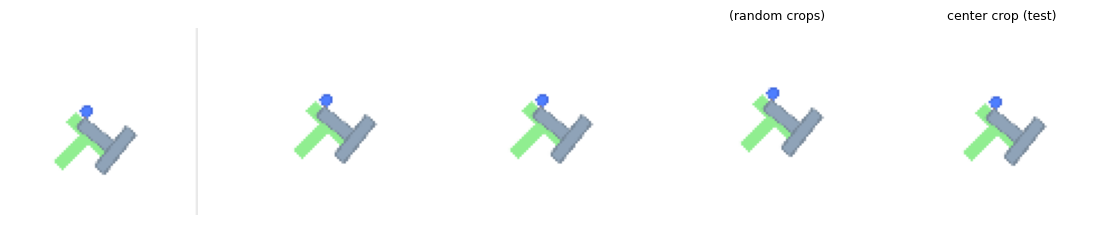

batches per epoch: 400 (batch size 64, as in Appendix A.4 for image-based)


In [24]:
class PushTImageDataset(Dataset):
    def __init__(self, train=True):
        self.train = train

    def __len__(self):
        return N

    def __getitem__(self, i):
        s, e = ep_start[i], ep_end[i]
        obs_idx = np.clip(np.arange(i - T_o + 1, i + 1), s, e - 1)
        act_idx = np.clip(np.arange(i, i + T_p),         s, e - 1)

        if self.train:
            top, left = np.random.randint(0, 13, size=2)     # random corner, 0..12
        else:
            top, left = 6, 6                                  # center crop
        img = imgs[obs_idx][:, top:top + 84, left:left + 84]  # (2, 84, 84, 3) uint8
        img = torch.from_numpy(img).permute(0, 3, 1, 2).float() / 255.0 * 2 - 1

        return {
            "image":     img,                                                        # (2, 3, 84, 84)
            "agent_pos": torch.from_numpy(obs_norm[obs_idx, 18:20].astype(np.float32)),   # (2, 2)
            "action":    torch.from_numpy(action_norm[act_idx].astype(np.float32)),       # (16, 2)
        }

img_dataset = PushTImageDataset(train=True)
img_loader  = DataLoader(img_dataset, batch_size=64, shuffle=True, num_workers=2, drop_last=True)

b = next(iter(img_loader))
for k_, v_ in b.items():
    print(f"{k_:10s}", tuple(v_.shape), v_.dtype, " range", round(v_.min().item(), 2), "to", round(v_.max().item(), 2))

# the same frame five times: the random crops differ a little, the last one is the test-time center crop
i = int(starts[3]) + 40
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax in axes[:4]:
    im = img_dataset[i]["image"][1]                       # latest frame of the window
    ax.imshow(((im.permute(1, 2, 0) + 1) / 2).numpy()); ax.axis("off")
axes[3].set_title("(random crops)", fontsize=9)
test_ds = PushTImageDataset(train=False)
im = test_ds[i]["image"][1]
axes[4].imshow(((im.permute(1, 2, 0) + 1) / 2).numpy()); axes[4].axis("off"); axes[4].set_title("center crop (test)", fontsize=9)
plt.show()
print("batches per epoch:", len(img_loader), "(batch size 64, as in Appendix A.4 for image-based)")

### ResNet-18 encoder
A ResNet-18 trained **from scratch** (no pretraining). Every BatchNorm is replaced by GroupNorm (BatchNorm does not work well with EMA), and the global pooling and classifier are removed so the output keeps its 3×3 spatial layout.

In [25]:
import torchvision

def make_resnet18_gn():
    net = torchvision.models.resnet18(weights=None)            # no pretraining
    def to_gn(module):                                          # swap every BatchNorm for GroupNorm
        for name, child in module.named_children():
            if isinstance(child, nn.BatchNorm2d):
                setattr(module, name, nn.GroupNorm(child.num_features // 16, child.num_features))
            else:
                to_gn(child)
    to_gn(net)
    # keep only the convolutional part: no global average pooling, no classifier
    return nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool,
                         net.layer1, net.layer2, net.layer3, net.layer4)

backbone = make_resnet18_gn()

x = torch.randn(8, 3, 84, 84)
y = backbone(x)
print("input  :", tuple(x.shape))
print("output :", tuple(y.shape), "  (batch, channels, grid height, grid width)")
print("BatchNorm layers left:", sum(isinstance(m, nn.BatchNorm2d) for m in backbone.modules()))
print("GroupNorm layers     :", sum(isinstance(m, nn.GroupNorm)   for m in backbone.modules()))
print("parameters:", f"{sum(p.numel() for p in backbone.parameters()):,}")

input  : (8, 3, 84, 84)
output : (8, 512, 3, 3)   (batch, channels, grid height, grid width)
BatchNorm layers left: 0
GroupNorm layers     : 20
parameters: 11,176,512


### Spatial softmax
Replaces global average pooling: a 1×1 convolution turns the 512 feature maps into 32 keypoint maps, and a softmax over positions gives the expected (x, y) location of each keypoint, so each frame becomes 64 numbers that say *where* things are.

In [26]:
class SpatialSoftmax(nn.Module):
    def __init__(self, in_ch=512, num_kp=32, h=3, w=3):
        super().__init__()
        self.kp_conv = nn.Conv2d(in_ch, num_kp, 1)             # 512 feature maps -> 32 keypoint maps
        ys, xs = torch.meshgrid(torch.linspace(-1, 1, h), torch.linspace(-1, 1, w), indexing="ij")
        self.register_buffer("pos", torch.stack([xs.flatten(), ys.flatten()], dim=-1))   # (h*w, 2): x, y of each cell

    def forward(self, f):                                       # f: (B, 512, 3, 3)
        scores  = self.kp_conv(f).flatten(2)                    # (B, K, 9)
        weights = scores.softmax(dim=-1)                        # how much of each cell
        kp = weights @ self.pos                                 # (B, K, 2): weighted average position
        return kp.flatten(1)                                    # (B, 2K)

# tests with a known answer: one cell lights up, the keypoint should land on that cell
t = SpatialSoftmax(in_ch=1, num_kp=1)
with torch.no_grad():
    t.kp_conv.weight.fill_(100.); t.kp_conv.bias.zero_()        # make the peak sharp

f = torch.zeros(1, 1, 3, 3); f[0, 0, 0, 2] = 1.0                # top-right cell
print("peak in top-right cell -> (x, y) =", t(f).detach().numpy().round(2))
f = torch.zeros(1, 1, 3, 3); f[0, 0, 1, 1] = 1.0                # center cell
print("peak in center cell    -> (x, y) =", t(f).detach().numpy().round(2))

# the full encoder so far: picture -> ResNet-18 features -> 32 keypoints
ss = SpatialSoftmax()
kp_out = ss(backbone(torch.randn(8, 3, 84, 84)))
print("pictures -> keypoints:", tuple(kp_out.shape))

peak in top-right cell -> (x, y) = [[ 1. -1.]]
peak in center cell    -> (x, y) = [[0. 0.]]
pictures -> keypoints: (8, 64)


### Image encoder and image policy
`ImageObsEncoder` turns each frame into 66 numbers (64 keypoint coordinates + pusher position). `ImagePolicy` feeds the 2×66 = 132 numbers into the same conditional U-Net as before. Also contains a small benchmark to compare speed and memory of network sizes.

In [28]:
class ImageObsEncoder(nn.Module):
    def __init__(self, num_kp=32):
        super().__init__()
        self.backbone = make_resnet18_gn()
        self.spatial_softmax = SpatialSoftmax(512, num_kp)
        self.out_dim_per_step = 2 * num_kp + 2          # keypoints (x, y) + pusher position

    def forward(self, image, agent_pos):                # (B, T, 3, 84, 84), (B, T, 2)
        B, T = image.shape[:2]
        f  = self.backbone(image.flatten(0, 1))         # every frame separately: (B*T, 512, 3, 3)
        kp = self.spatial_softmax(f).view(B, T, -1)     # (B, T, 64)
        return torch.cat([kp, agent_pos], dim=-1)       # (B, T, 66)

class ImagePolicy(nn.Module):
    def __init__(self, down_dims=(256, 512, 1024), num_kp=32, T_o=2):
        super().__init__()
        self.encoder = ImageObsEncoder(num_kp)
        self.unet = ConditionalUnet1D(obs_dim=T_o * self.encoder.out_dim_per_step, down_dims=down_dims)

    def encode(self, image, agent_pos):
        return self.encoder(image, agent_pos)

    def forward(self, noisy_action, k, image, agent_pos):
        return self.unet(noisy_action, k, self.encode(image, agent_pos))


def bench_image_policy(down_dims, bf16, n=15, warm=3, bs=64):
    m = ImagePolicy(down_dims).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4, weight_decay=1e-6, betas=(0.95, 0.999))
    img = torch.randn(bs, 2, 3, 84, 84, device=device)
    pos = torch.randn(bs, 2, 2, device=device)
    act = torch.randn(bs, 16, 2, device=device)
    torch.cuda.reset_peak_memory_stats()
    for i in range(warm + n):
        if i == warm:
            torch.cuda.synchronize(); t0 = time.time()
        k = torch.randint(0, K, (bs,), device=device)
        noise = torch.randn_like(act)
        noisy = torch.sqrt(ab[k])[:, None, None] * act + torch.sqrt(1 - ab[k])[:, None, None] * noise
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=bf16):
            pred = m(noisy, k, img, pos)
        loss = torch.nn.functional.mse_loss(pred.float(), noise)
        opt.zero_grad(); loss.backward(); opt.step()
    torch.cuda.synchronize()
    s = (time.time() - t0) / n
    mem = torch.cuda.max_memory_allocated() / 1e9
    del m, opt; torch.cuda.empty_cache()
    return s, mem

STEPS_OFFICIAL = 3050 * 400          # 3050 epochs x 400 steps (batch 64)
for dd in [(256, 512, 1024), (512, 1024, 2048)]:
    for bf16 in [False, True]:
        s, mem = bench_image_policy(dd, bf16)
        print(f"U-Net {dd} | {'bf16' if bf16 else 'fp32'} | {s:.3f} s/step | {mem:.1f} GB | "
              f"{s * 400 / 60:.1f} min/epoch | official 3050 epochs would take {s * STEPS_OFFICIAL / 3600:.0f} h")

U-Net (256, 512, 1024) | fp32 | 0.400 s/step | 9.1 GB | 2.7 min/epoch | official 3050 epochs would take 136 h
U-Net (256, 512, 1024) | bf16 | 1.470 s/step | 9.3 GB | 9.8 min/epoch | official 3050 epochs would take 498 h
U-Net (512, 1024, 2048) | fp32 | 1.551 s/step | 12.7 GB | 10.3 min/epoch | official 3050 epochs would take 526 h
U-Net (512, 1024, 2048) | bf16 | 3.468 s/step | 12.8 GB | 23.1 min/epoch | official 3050 epochs would take 1175 h


### Image training setup
Sets the paper-size U-Net (512/1024/2048), AdamW with betas (0.95, 0.999), cosine schedule with warm-up, EMA, and the image `train_step_img` (same noise-prediction loss as before, but the encoder is trained together with the U-Net). Includes a speed benchmark.

In [29]:
IMG_DOWN_DIMS = (512, 1024, 2048)      # paper size (255.6M U-Net). Use (256, 512, 1024) for a lighter run.
IMG_EPOCHS    = 3050                   # official value; we will decide the real budget after the smoke test
IMG_STEPS_PER_EPOCH = len(img_loader)
IMG_TOTAL_STEPS = IMG_EPOCHS * IMG_STEPS_PER_EPOCH
IMG_WARMUP = 500

def build_image_training():
    global img_policy, img_ema, opt_img, sched_img, img_step
    img_policy = ImagePolicy(IMG_DOWN_DIMS).to(device)
    img_ema = copy.deepcopy(img_policy).eval()
    for p in img_ema.parameters():
        p.requires_grad_(False)
    opt_img = torch.optim.AdamW(img_policy.parameters(), lr=1e-4, weight_decay=1e-6, betas=(0.95, 0.999))
    def lr_lambda_img(step):
        if step < IMG_WARMUP:
            return (step + 1) / IMG_WARMUP
        progress = (step - IMG_WARMUP) / max(1, IMG_TOTAL_STEPS - IMG_WARMUP)
        return 0.5 * (1 + math.cos(math.pi * progress))
    sched_img = torch.optim.lr_scheduler.LambdaLR(opt_img, lr_lambda_img)
    img_step = 0

def update_img_ema(step, max_decay=0.9999):
    decay = min(max_decay, (1 + step) / (10 + step))
    with torch.no_grad():
        for p_e, p in zip(img_ema.parameters(), img_policy.parameters()):
            p_e.mul_(decay).add_(p, alpha=1 - decay)

def train_step_img(batch):
    global img_step
    image = batch["image"].to(device, non_blocking=True)        # (B, 2, 3, 84, 84)
    pos   = batch["agent_pos"].to(device, non_blocking=True)    # (B, 2, 2)
    a0    = batch["action"].to(device, non_blocking=True)       # (B, 16, 2)
    B = a0.shape[0]
    k     = torch.randint(0, K, (B,), device=device)
    noise = torch.randn_like(a0)
    ab_k  = ab[k][:, None, None]
    noisy = torch.sqrt(ab_k) * a0 + torch.sqrt(1 - ab_k) * noise
    loss  = torch.nn.functional.mse_loss(img_policy(noisy, k, image, pos), noise)    # Eq. 5
    opt_img.zero_grad(); loss.backward(); opt_img.step(); sched_img.step()
    update_img_ema(img_step); img_step += 1
    return loss.item()

def benchmark_image_training(n=30, warm=3):
    it = iter(img_loader)
    for _ in range(warm):
        train_step_img(next(it))
    if device == "cuda": torch.cuda.synchronize()
    t_wait, t0 = 0.0, time.time()
    for _ in range(n):
        t1 = time.time(); batch = next(it); t_wait += time.time() - t1
        train_step_img(batch)
    if device == "cuda": torch.cuda.synchronize()
    s = (time.time() - t0) / n
    print(f"{s:.3f} s/step total | {t_wait / n:.3f} s/step waiting for data | "
          f"{s * IMG_STEPS_PER_EPOCH / 60:.1f} min/epoch | {s * IMG_TOTAL_STEPS / 3600:.0f} h for {IMG_EPOCHS} epochs")

build_image_training()
print("parameters:", f"{sum(p.numel() for p in img_policy.parameters()):,}")
benchmark_image_training()

parameters: 266,768,738
1.634 s/step total | 0.006 s/step waiting for data | 10.9 min/epoch | 554 h for 3050 epochs


### Image run management
`setup_image_run` sets the schedule length and the checkpoint folder, builds fresh models and **resumes from `latest.pt`** if it exists. `save_image_checkpoints` saves the full state (`latest.pt`: model, EMA, optimizer, scheduler, loss history) plus small half-precision EMA snapshots for evaluation. `run_training_img` is the training loop. The commented lines at the end are the 30-epoch smoke test that was run first.

In [42]:
import os

def setup_image_run(epochs, subdir, save_every=50):
    """Set the schedule length and checkpoint folder, build fresh models, resume from latest.pt if it exists."""
    global IMG_EPOCHS, IMG_TOTAL_STEPS, IMG_CKPT_DIR, IMG_SAVE_EVERY, img_start_epoch, img_epoch_losses
    IMG_EPOCHS = epochs
    IMG_TOTAL_STEPS = IMG_EPOCHS * IMG_STEPS_PER_EPOCH
    IMG_SAVE_EVERY = save_every
    IMG_CKPT_DIR = os.path.join(str(CKPT_DIR), subdir)
    os.makedirs(IMG_CKPT_DIR, exist_ok=True)
    build_image_training()
    img_start_epoch, img_epoch_losses = 0, []
    latest = os.path.join(IMG_CKPT_DIR, "latest.pt")
    if os.path.exists(latest):
        ck = torch.load(latest, map_location="cpu")        # the weights are copied to the GPU by load_state_dict
        img_policy.load_state_dict(ck["policy"]); img_ema.load_state_dict(ck["ema"])
        opt_img.load_state_dict(ck["opt"]);       sched_img.load_state_dict(ck["sched"])
        global img_step
        img_step, img_start_epoch, img_epoch_losses = ck["step"], ck["epoch"], ck["epoch_losses"]
        print(f"resumed from epoch {img_start_epoch} (step {img_step})")
    else:
        print("starting fresh")
    print(f"schedule: {IMG_EPOCHS} epochs x {IMG_STEPS_PER_EPOCH} steps = {IMG_TOTAL_STEPS} steps | folder: {IMG_CKPT_DIR}")

def save_image_checkpoints(epoch):
    tmp = os.path.join(IMG_CKPT_DIR, "latest.tmp")
    torch.save({"epoch": epoch, "step": img_step, "epoch_losses": img_epoch_losses,
                "policy": img_policy.state_dict(), "ema": img_ema.state_dict(),
                "opt": opt_img.state_dict(), "sched": sched_img.state_dict(),
                "down_dims": IMG_DOWN_DIMS}, tmp)
    os.replace(tmp, os.path.join(IMG_CKPT_DIR, "latest.pt"))
    if epoch % 250 == 0 or epoch > IMG_EPOCHS - 500:             # small fp16 EMA snapshots for evaluation
        ema16 = {k_: v.half() for k_, v in img_ema.state_dict().items()}
        torch.save({"epoch": epoch, "ema": ema16, "down_dims": IMG_DOWN_DIMS},
                   os.path.join(IMG_CKPT_DIR, f"ema_epoch_{epoch:04d}.pt"))

def run_training_img(stop_after_hours=None):
    global img_start_epoch
    t_start = time.time()
    for epoch in range(img_start_epoch + 1, IMG_EPOCHS + 1):
        img_policy.train()
        losses = [train_step_img(batch) for batch in img_loader]
        img_epoch_losses.append(float(np.mean(losses)))
        if epoch == img_start_epoch + 1 or epoch % 5 == 0:
            done = epoch - img_start_epoch
            elapsed = (time.time() - t_start) / 3600
            left = elapsed / done * (IMG_EPOCHS - epoch)
            print(f"epoch {epoch:4d}/{IMG_EPOCHS}  loss {img_epoch_losses[-1]:.4f}  "
                  f"lr {sched_img.get_last_lr()[0]:.2e}  elapsed {elapsed:.2f}h  est. remaining {left:.1f}h")
        out_of_time = stop_after_hours and (time.time() - t_start) / 3600 >= stop_after_hours
        if epoch % IMG_SAVE_EVERY == 0 or epoch == IMG_EPOCHS or out_of_time:
            save_image_checkpoints(epoch)
            print(f"  -> checkpoint saved at epoch {epoch}")
        if out_of_time:
            print("stopping as requested; call setup_image_run(...) again with the same arguments to resume")
            break

# # ---- smoke test: 30 epochs, compressed schedule, own folder ----
# setup_image_run(epochs=30, subdir="image_smoke", save_every=10)
# run_training_img()


### Sampler constants on the GPU
Recreates the diffusion constants (`alphas`, `betas`, previous alpha-bar) on the GPU, which was needed again after a restart.

In [34]:
alphas_d = alphas.to(device)
betas_d  = betas.to(device)
ab_prev  = torch.cat([torch.ones(1), alphas_cumprod[:-1]]).to(device)
print("ready:", ab_prev.shape, alphas_d.shape, betas_d.shape)

ready: torch.Size([100]) torch.Size([100]) torch.Size([100])


### Image evaluation
Prepares observations for evaluation (center crop, scale to [-1, 1], normalise the pusher position), defines the image sampler (the pictures are encoded **once** per plan, only the U-Net runs for the 100 steps) and `evaluate_img`, then two checks: (1) the simulator's pictures and the dataset's pictures have the same pixel range and look alike, (2) a 30-epoch smoke checkpoint is evaluated on 10 test seeds to confirm the whole pipeline runs.

simulator picture: min 0.255 max 1.0
dataset picture  : min 0.255 max 1.0


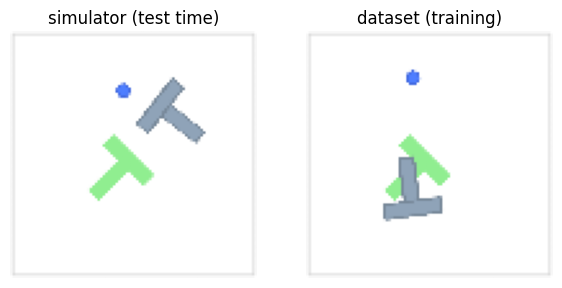

loaded EMA from epoch 30
smoke checkpoint (30 epochs), 10 test seeds: [0.98 1.   0.52 0.71 0.95 1.   0.69 1.   0.7  1.  ] | mean 0.856 | 123 s


In [35]:
from diffusion_policy.env.pusht.pusht_image_env import PushTImageEnv

pos_stats = {"min": obs_stats["min"][18:20], "max": obs_stats["max"][18:20]}      # pusher-position part of the old stats

def prep_obs(img_hist, pos_hist):
    """Last T_o frames -> network input: center crop 84x84, scale to [-1, 1]; pusher positions normalized."""
    im = np.stack(img_hist)[:, :, 6:90, 6:90] * 2 - 1                              # (T, 3, 84, 84)
    ps = normalize(np.stack(pos_hist), pos_stats)                                   # (T, 2)
    return im.astype(np.float32), ps.astype(np.float32)

@torch.no_grad()
def sample_img(policy, image, agent_pos):
    """image: (B, 2, 3, 84, 84), agent_pos: (B, 2, 2) -> (B, 16, 2) normalized actions."""
    B = image.shape[0]
    feats = policy.encode(image, agent_pos)                        # the picture is the same for all 100 steps: encode once
    x = torch.randn(B, 16, 2, device=device)
    for k in reversed(range(K)):
        kk  = torch.full((B,), k, device=device, dtype=torch.long)
        eps = policy.unet(x, kk, feats)
        x0 = ((x - torch.sqrt(1 - ab[k]) * eps) / torch.sqrt(ab[k])).clamp(-1, 1)
        coef1 = torch.sqrt(ab_prev[k]) * betas_d[k] / (1 - ab[k])
        coef2 = torch.sqrt(alphas_d[k]) * (1 - ab_prev[k]) / (1 - ab[k])
        mean  = coef1 * x0 + coef2 * x
        if k > 0:
            var = betas_d[k] * (1 - ab_prev[k]) / (1 - ab[k])
            x = mean + torch.sqrt(var) * torch.randn_like(x)
        else:
            x = mean
    return x

@torch.no_grad()
def evaluate_img(policy, seeds, max_steps=300, T_o=2, T_a=8):
    envs = []
    for s in seeds:
        e = PushTImageEnv(legacy=True, render_size=96)
        e.seed(s)
        envs.append(e)
    first = [e.reset() for e in envs]
    img_hist = [[o["image"]] * T_o for o in first]
    pos_hist = [[o["agent_pos"]] * T_o for o in first]
    max_r = np.zeros(len(envs)); steps = np.zeros(len(envs), dtype=int); done = np.zeros(len(envs), dtype=bool)

    while not done.all():
        active = [i for i in range(len(envs)) if not done[i]]
        pairs = [prep_obs(img_hist[i][-T_o:], pos_hist[i][-T_o:]) for i in active]
        image = torch.from_numpy(np.stack([p[0] for p in pairs])).to(device)
        apos  = torch.from_numpy(np.stack([p[1] for p in pairs])).to(device)
        plans = unnormalize(sample_img(policy, image, apos).cpu().numpy(), action_stats)
        for j, i in enumerate(active):
            for a in plans[j, :T_a]:
                o, r, d, _ = envs[i].step(a)
                img_hist[i].append(o["image"]); pos_hist[i].append(o["agent_pos"])
                max_r[i] = max(max_r[i], r); steps[i] += 1
                if d or steps[i] >= max_steps:
                    done[i] = True
                    break
    return max_r

def load_img_ema(path):
    ck = torch.load(path, map_location="cpu")
    m = ImagePolicy(tuple(ck["down_dims"]))
    m.load_state_dict({k_: v.float() for k_, v in ck["ema"].items()})
    print("loaded EMA from epoch", ck["epoch"])
    return m.to(device).eval()

# 1) simulator picture vs dataset picture
e = PushTImageEnv(legacy=True, render_size=96); e.seed(100000)
sim_img = e.reset()["image"]                                       # (3, 96, 96) in [0, 1]
ds_img  = imgs[int(starts[0])].astype(np.float32) / 255            # (96, 96, 3)
print("simulator picture: min", sim_img.min().round(3), "max", sim_img.max().round(3))
print("dataset picture  : min", ds_img.min().round(3),  "max", ds_img.max().round(3))
fig, ax = plt.subplots(1, 2, figsize=(7, 3.6))
ax[0].imshow(np.moveaxis(sim_img, 0, -1)); ax[0].set_title("simulator (test time)")
ax[1].imshow(ds_img);                      ax[1].set_title("dataset (training)")
for a_ in ax: a_.axis("off")
plt.show()

# 2) quick pipeline check with the 30-epoch smoke checkpoint, 10 test seeds
smoke = load_img_ema(f"{CKPT_DIR}/image_smoke/ema_epoch_0030.pt")
torch.manual_seed(0)
t0 = time.time()
r = evaluate_img(smoke, list(range(100000, 100010)))
print("smoke checkpoint (30 epochs), 10 test seeds:", np.round(r, 2), "| mean", round(float(r.mean()), 3), f"| {time.time()-t0:.0f} s")

### Free GPU memory
Deletes leftover models and optimizers from earlier cells and empties the CUDA cache. Needed because a smaller GPU ran out of memory when everything was kept in memory at once.

In [41]:
import gc
for name in ["img_policy", "img_ema", "opt_img", "sched_img", "smoke", "net", "ema_net", "optimizer", "raw_model", "model", "ck"]:
    if name in globals():
        del globals()[name]
gc.collect(); torch.cuda.empty_cache()

print("GPU:", torch.cuda.get_device_name(0))
free, total = torch.cuda.mem_get_info()
print(f"free {free/1e9:.1f} GB of {total/1e9:.1f} GB | held by this process: {torch.cuda.memory_allocated()/1e9:.1f} GB")

GPU: Tesla T4
free 13.9 GB of 15.6 GB | held by this process: 1.1 GB


> **Note:** this launch cell was interrupted (`KeyboardInterrupt`) when GPU quota ran out at epoch ~300 of the planned 800-epoch schedule. The 300-epoch checkpoint is what is evaluated below.

### Launch image training
Starts (or resumes) the image run with an 800-epoch cosine schedule (this launch was written with `epochs=500`). It was stopped at about epoch 300 when the GPU quota ran out, as the note above says.

In [44]:
setup_image_run(epochs=500, subdir="image_run_800", save_every=50)
run_training_img()


## Part 5 · Results and videos
### Evaluate the image policy
Loads the epoch-250 and epoch-300 EMA models, evaluates each on the 6 training and 50 test seeds, saves the numbers to `image_eval.json` and prints the per-seed test scores of epoch 300.

In [45]:
import json, gc

def load_img_ema_from_latest(path):
    ck = torch.load(path, map_location="cpu")                       # the EMA weights are inside latest.pt
    m = ImagePolicy(tuple(ck["down_dims"]))
    m.load_state_dict(ck["ema"])
    print("loaded EMA from epoch", ck["epoch"])
    return m.to(device).eval()

TRAIN_SEEDS = list(range(0, 6))
TEST_SEEDS  = list(range(100000, 100050))
IMG_DIR = f"{CKPT_DIR}/image_run_800"

img_results = {}
t0 = time.time()
for name, loader_fn in [("epoch 250", lambda: load_img_ema(f"{IMG_DIR}/ema_epoch_0250.pt")),
                        ("epoch 300", lambda: load_img_ema_from_latest(f"{IMG_DIR}/latest.pt"))]:
    pol = loader_fn()
    torch.manual_seed(0)
    r_tr = evaluate_img(pol, TRAIN_SEEDS)
    r_te = evaluate_img(pol, TEST_SEEDS)
    img_results[name] = {"train": r_tr.tolist(), "test": r_te.tolist()}
    print(f"image policy, {name} | train-seed score {r_tr.mean():.3f} | test-seed score {r_te.mean():.3f} | {time.time()-t0:.0f} s")
    del pol; gc.collect(); torch.cuda.empty_cache()

with open(f"{IMG_DIR}/image_eval.json", "w") as f:
    json.dump(img_results, f)
print("test scores per seed (epoch 300):", np.round(img_results["epoch 300"]["test"], 2))

loaded EMA from epoch 250
image policy, epoch 250 | train-seed score 0.993 | test-seed score 0.981 | 410 s
loaded EMA from epoch 300
image policy, epoch 300 | train-seed score 0.990 | test-seed score 0.987 | 836 s
test scores per seed (epoch 300): [1.   1.   1.   1.   0.99 1.   0.97 1.   1.   1.   0.99 1.   0.97 1.
 1.   0.96 0.98 0.63 1.   0.97 1.   1.   1.   1.   1.   1.   1.   0.99
 1.   1.   1.   1.   0.98 1.   1.   1.   1.   1.   0.93 1.   0.99 1.
 1.   1.   1.   1.   0.98 1.   1.   1.  ]


### Side-by-side videos
Rolls out the state policy (epoch 4500) and the image policy (epoch 300) on the same seeds in a large-render twin environment, draws the pusher target and a score header, and writes one `.mp4` per seed (100000, 100001, 100003) with both policies side by side.

In [46]:
!pip -q install imageio imageio-ffmpeg

from diffusion_policy.env.pusht.pusht_keypoints_env import PushTKeypointsEnv
kp = PushTKeypointsEnv.genenerate_keypoint_manager_params()

import imageio.v2 as imageio, cv2
from diffusion_policy.env.pusht.pusht_env import PushTEnv

@torch.no_grad()
def ddpm_sample(eps_fn, B=1):
    """100-step DDPM sampler; eps_fn(x, k) returns the predicted noise."""
    x = torch.randn(B, 16, 2, device=device)
    for k in reversed(range(K)):
        kk  = torch.full((B,), k, device=device, dtype=torch.long)
        eps = eps_fn(x, kk)
        x0 = ((x - torch.sqrt(1 - ab[k]) * eps) / torch.sqrt(ab[k])).clamp(-1, 1)
        coef1 = torch.sqrt(ab_prev[k]) * betas_d[k] / (1 - ab[k])
        coef2 = torch.sqrt(alphas_d[k]) * (1 - ab_prev[k]) / (1 - ab[k])
        mean  = coef1 * x0 + coef2 * x
        if k > 0:
            var = betas_d[k] * (1 - ab_prev[k]) / (1 - ab[k])
            x = mean + torch.sqrt(var) * torch.randn_like(x)
        else:
            x = mean
    return x

def state_plan_fn(model):
    def plan(hist):
        o = normalize(np.stack(hist["obs"][-2:]), obs_stats).astype(np.float32)
        obs_b = torch.from_numpy(o)[None].to(device)
        p = ddpm_sample(lambda x, kk: model(x, kk, obs_b))[0].cpu().numpy()
        return unnormalize(p, action_stats)
    return plan

def image_plan_fn(policy):
    def plan(hist):
        im, ps = prep_obs(hist["img"][-2:], hist["pos"][-2:])
        im = torch.from_numpy(im)[None].to(device); ps = torch.from_numpy(ps)[None].to(device)
        feats = policy.encode(im, ps)
        p = ddpm_sample(lambda x, kk: policy.unet(x, kk, feats))[0].cpu().numpy()
        return unnormalize(p, action_stats)
    return plan

@torch.no_grad()
def rollout_with_video(plan_fn, kind, seed, max_steps=300, T_a=8, size=384):
    """Runs one episode; returns (frames, rewards). A second, large-resolution twin env renders the same actions."""
    env = PushTKeypointsEnv(legacy=True, render_size=96, **kp) if kind == "state" else PushTImageEnv(legacy=True, render_size=96)
    viz = PushTEnv(legacy=True, render_size=size, render_action=False)   # we draw the target marker ourselves
    env.seed(seed); viz.seed(seed)
    o = env.reset(); viz.reset()
    hist = {"obs": [], "img": [], "pos": []}
    def add(o):
        if kind == "state": hist["obs"].append(o[:20])
        else: hist["img"].append(o["image"]); hist["pos"].append(o["agent_pos"])
    add(o); add(o)                                           # pad the first observation, as in training
    frames, rewards, steps, done = [viz.render("rgb_array")], [0.0], 0, False
    while steps < max_steps and not done:
        plan = plan_fn(hist)
        for a in plan[:T_a]:
            o, r, done, _ = env.step(a); viz.step(a)
            add(o)
            fr = np.ascontiguousarray(viz.render("rgb_array").copy())
            cv2.drawMarker(fr, (int(a[0] / 512 * size), int(a[1] / 512 * size)), (230, 30, 30), cv2.MARKER_CROSS, 14, 2)   # where the policy tells the pusher to go
            frames.append(fr); rewards.append(float(r)); steps += 1
            if done or steps >= max_steps:
                break
    return frames, rewards

def side_by_side(runs, path, fps=10, hold=15):
    """runs: list of (title, frames, rewards). Writes one mp4; a finished episode holds its last frame."""
    n = max(len(f) for _, f, _ in runs) + hold
    out = []
    for t in range(n):
        panels = []
        for title, frames, rewards in runs:
            i = min(t, len(frames) - 1)
            img = np.ascontiguousarray(frames[i].copy())
            band = np.full((44, img.shape[1], 3), 255, dtype=np.uint8)
            best = max(rewards[:i + 1])
            cv2.putText(band, title, (8, 17), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (30, 30, 30), 1, cv2.LINE_AA)
            cv2.putText(band, f"score so far {best:.2f}" + ("   SUCCESS" if best >= 1.0 else ""), (8, 37),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 120, 0) if best >= 1.0 else (90, 90, 90), 1, cv2.LINE_AA)
            panels.append(np.vstack([band, img]))
        out.append(np.hstack(panels))
    w = imageio.get_writer(path, fps=fps, codec="libx264", macro_block_size=None, quality=8)
    for fr in out: w.append_data(fr)
    w.close()
    return len(out)

# the two policies
state_model = ConditionalUnet1D(down_dims=(256, 512, 1024)).to(device)
ck = torch.load(f"{CKPT_DIR}/ema_epoch_4500.pt", map_location="cpu")
state_model.load_state_dict({k_: v.float() for k_, v in ck["ema"].items()}); state_model.eval()
image_model = load_img_ema_from_latest(f"{IMG_DIR}/latest.pt")

VIDEO_SEEDS = [100000, 100001, 100003]
os.makedirs(f"{CKPT_DIR}/videos", exist_ok=True)
for seed in VIDEO_SEEDS:
    torch.manual_seed(seed)
    fs, rs = rollout_with_video(state_plan_fn(state_model), "state", seed)
    fi, ri = rollout_with_video(image_plan_fn(image_model), "image", seed)
    path = f"{CKPT_DIR}/videos/pusht_seed{seed}_state_vs_image.mp4"
    side_by_side([(f"State-based DP (4500 epochs)  seed {seed}", fs, rs),
                  (f"Image-based DP (300 epochs)  seed {seed}", fi, ri)], path)
    print(f"seed {seed}: state score {max(rs):.2f} ({len(fs)-1} steps) | image score {max(ri):.2f} ({len(fi)-1} steps) -> {path}")

/content/diffusion_policy_official/diffusion_policy/env/pusht/pymunk_keypoint_manager.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10')
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


loaded EMA from epoch 300


/usr/local/lib/python3.13/dist-packages/gym/core.py:43: DeprecationWarning: WARN: The argument mode in render method is deprecated; use render_mode during environment initialization instead.
See here for more information: https://www.gymlibrary.ml/content/api/
  deprecation(


seed 100000: state score 1.00 (145 steps) | image score 0.97 (300 steps) -> /content/drive/MyDrive/pusht_diffusion/checkpoints/videos/pusht_seed100000_state_vs_image.mp4
seed 100001: state score 1.00 (159 steps) | image score 1.00 (182 steps) -> /content/drive/MyDrive/pusht_diffusion/checkpoints/videos/pusht_seed100001_state_vs_image.mp4
seed 100003: state score 0.18 (300 steps) | image score 1.00 (118 steps) -> /content/drive/MyDrive/pusht_diffusion/checkpoints/videos/pusht_seed100003_state_vs_image.mp4
